In [1]:
#import the data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
plt.style.use('ggplot')
from matplotlib.pyplot import figure
%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)

In [2]:
#load the data
traders_positions = pd.read_csv('data/raw/closed_positions_pnl.csv')
transaction = pd.read_csv('data/raw/individual_trades.csv')
markets = pd.read_csv('data/raw/markets_clean.csv')

In [3]:
transaction.head(10000)

,proxyWallet,side,asset,conditionId,size,price,timestamp,title,slug,icon,...,outcome,outcomeIndex,name,pseudonym,bio,profileImage,profileImageOptimized,transactionHash,source_condition_id,source_market_question
0,0x8ae599cc1fdeb17c95e2af00bd75a38034bd4f22,SELL,4487178524996566135404052070869519758309644689...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,500.000000,0.999000,1788955855,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5,kor-gwa-jej-2026-09-09-team-total-away-0pt5,https://polymarket-upload.s3.us-east-2.amazona...,...,Over,0,0xjames,NaN,CHANCE-7EDEE8C0ECEBFB56,https://polymarket-upload.s3.us-east-2.amazona...,NaN,0x2b17f73247dc383a35ff80eb64afc9b2989fe5287083...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5
1,0x543b6b3d6b86c630e06a0cad3260b294a3806c81,BUY,4487178524996566135404052070869519758309644689...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,500.000000,0.999000,1788955855,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5,kor-gwa-jej-2026-09-09-team-total-away-0pt5,https://polymarket-upload.s3.us-east-2.amazona...,...,Over,0,Xander-XX,Honest-Textbook,NaN,https://polymarket-upload.s3.us-east-2.amazona...,NaN,0x2b17f73247dc383a35ff80eb64afc9b2989fe5287083...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5
2,0xdbdd45150249e229eb4ca8aa48a30dca21faa5de,BUY,6251912471363374258110472858058151520318122095...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,27.920000,0.250000,1788951642,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5,kor-gwa-jej-2026-09-09-team-total-away-0pt5,https://polymarket-upload.s3.us-east-2.amazona...,...,Under,1,0xdbdd45150249e229eB4cA8aa48A30Dca21Faa5de-175...,Vigilant-Environment,NaN,NaN,NaN,0x94b81933d0ef7081c9db91c99d4885f247fe6ee03c62...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5
3,0x8ae599cc1fdeb17c95e2af00bd75a38034bd4f22,BUY,4487178524996566135404052070869519758309644689...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,27.920000,0.750000,1788951642,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5,kor-gwa-jej-2026-09-09-team-total-away-0pt5,https://polymarket-upload.s3.us-east-2.amazona...,...,Over,0,0xjames,NaN,CHANCE-7EDEE8C0ECEBFB56,https://polymarket-upload.s3.us-east-2.amazona...,NaN,0x94b81933d0ef7081c9db91c99d4885f247fe6ee03c62...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5
4,0xbfd770b7ff07fb2ece41b0e7c593db65a84cf0bf,BUY,6251912471363374258110472858058151520318122095...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,56.000000,0.250000,1788951627,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5,kor-gwa-jej-2026-09-09-team-total-away-0pt5,https://polymarket-upload.s3.us-east-2.amazona...,...,Under,1,0xbfD770B7ff0,Trivial-Player,NaN,NaN,NaN,0x870b8549b7d21bcad19050deab13d15f57df1e473b47...,0xc7528fbf34f6690317786bb55ba14f6af6a388721f34...,Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1574,0xaf713cc7a7c644c6e047d5bb0fb27911b029c26b,BUY,1500293690756486862191396454928979959834087847...,0xd09f4b5af9dc068f972b153614fa86525fede1185445...,5.000000,0.460000,1775018391,"Solana Up or Down - April 1, 12:35AM-12:40AM ET",sol-updown-5m-1775018100,https://polymarket-upload.s3.us-east-2.amazona...,...,Down,1,Surgrip,Possible-Audience,NaN,NaN,NaN,0xfa4ff0cdc6c9adc219b30b69fca605530e6951c23ef6...,0xd09f4b5af9dc068f972b153614fa86525fede1185445...,"Solana Up or Down - April 1, 12:35AM-12:40AM ET"
1575,0xb27bc932bf8110d8f78e55da7d5f0497a18b5b82,BUY,1500293690756486862191396454928979959834087847...,0xd09f4b5af9dc068f972b153614fa86525fede1185445...,5.000000,0.460000,1775018391,"Solana Up or Down - April 1, 12:35AM-12:40AM ET",sol-updown-5m-1775018100,https://polymarket-upload.s3.us-east-2.amazona...,...,Down,1,NaN,NaN,NaN,NaN,NaN,0xfa4ff0cdc6c9adc219b30b69fca605530e6951c23ef6...,0xd09f4b5af9dc068f972b153614fa86525f

Cleaning the data

In [4]:
markets.duplicated().sum()#0 duplicated
#transaction[transaction.duplicated()] #10 duplicate
#traders_positions[traders_positions.duplicated()]#59

np.int64(0)

In [5]:
#transaction = transaction.drop_duplicates()
#traders_positions = traders_positions.drop_duplicates()

In [6]:
markets.isna().sum()
#transaction.isna().sum()
#drop the missing values
#transaction = transaction[transaction['timestamp'].notna()]

conditionId             0
question                0
outcomes                0
outcomePrices           0
volume                  0
liquidity              93
startDate               0
endDate                 0
closed                  0
active                  0
resolutionSource       22
series                  1
topic                   0
price_first_outcome     0
winner                  2
duration_days           0
dtype: int64

In [7]:
markets.shape
#transaction.shape

(100, 16)

lets start analysing , there is no missing data

In [8]:
#chage the time , to our time UTC+0
transaction['timestamp'] = pd.to_datetime(
    traders_positions['timestamp'],
    unit='s'
)

In [9]:
#transaction['timestamp'].max() #2026-10-11 18:08:04
transaction['timestamp'].min() #2026-02-05 20:57:57

Timestamp('2026-02-05 20:57:57')

In [10]:
top10_counts = transaction['conditionId'].value_counts().head(12)

In [11]:
top10_info = markets[
    markets['conditionId'].isin(top10_counts.index)
]

In [12]:
top10_info[['conditionId', 'topic']]

,conditionId,topic
5,0xbf71461fd70ca5e2d8decb4c5c4f263509d1c91881c7...,milan-daily-weather
10,0x2841779f532c7cb7a8554bc977b111bf65ba3f66646d...,saf1-games
11,0x470fd7fb83727af7f9a8a837c3232a3bfddee21a1430...,ned2-games
15,0xa6d544024ed0b1de9e0cd6c0327a7c18a872e5875f40...,counter-strike
17,0x9d95e6b2ce322c35b77c5a3f57fb27bd96b44a065da9...,atp-doubles
25,0x17ec8d1f73e5b824417661e80c933a46859b6081baec...,brazil-serie-b
43,0x8a1738b523cc775ca738048c76318c67696894e36c63...,la-liga-2025
44,0xd5939ee1d2c8cdf6257159e2cacec3593229658466d7...,other
66,0xf99d9289a082e5683d2c0573551b509a9a9d0a0dd5cd...,atp
67,0xf44477dbbe9c0daf06b1b3d332ed825cb9bbc82f964d...,atp


In [13]:
top10_results = top10_counts.rename('trade_count').rename_axis('conditionId').reset_index()

In [14]:
top10_results = top10_results.merge(
    top10_info,
    on='conditionId',
    how='left'
)
print(top10_results[['topic', 'trade_count']])

                       topic  trade_count
0             counter-strike          200
1   btc-multi-strikes-weekly          200
2          sol-up-or-down-5m          200
3                      other          104
4             brazil-serie-b           42
5                 saf1-games           28
6                 ned2-games           28
7               la-liga-2025           25
8                atp-doubles           24
9                        atp           20
10                       atp           20
11       milan-daily-weather           19


In [15]:
categories = ['Crypto','Esports','Other','Traditional Sports','Tennis','Weather']
counts = [400, 200, 104, 95, 64, 19]

make the plot

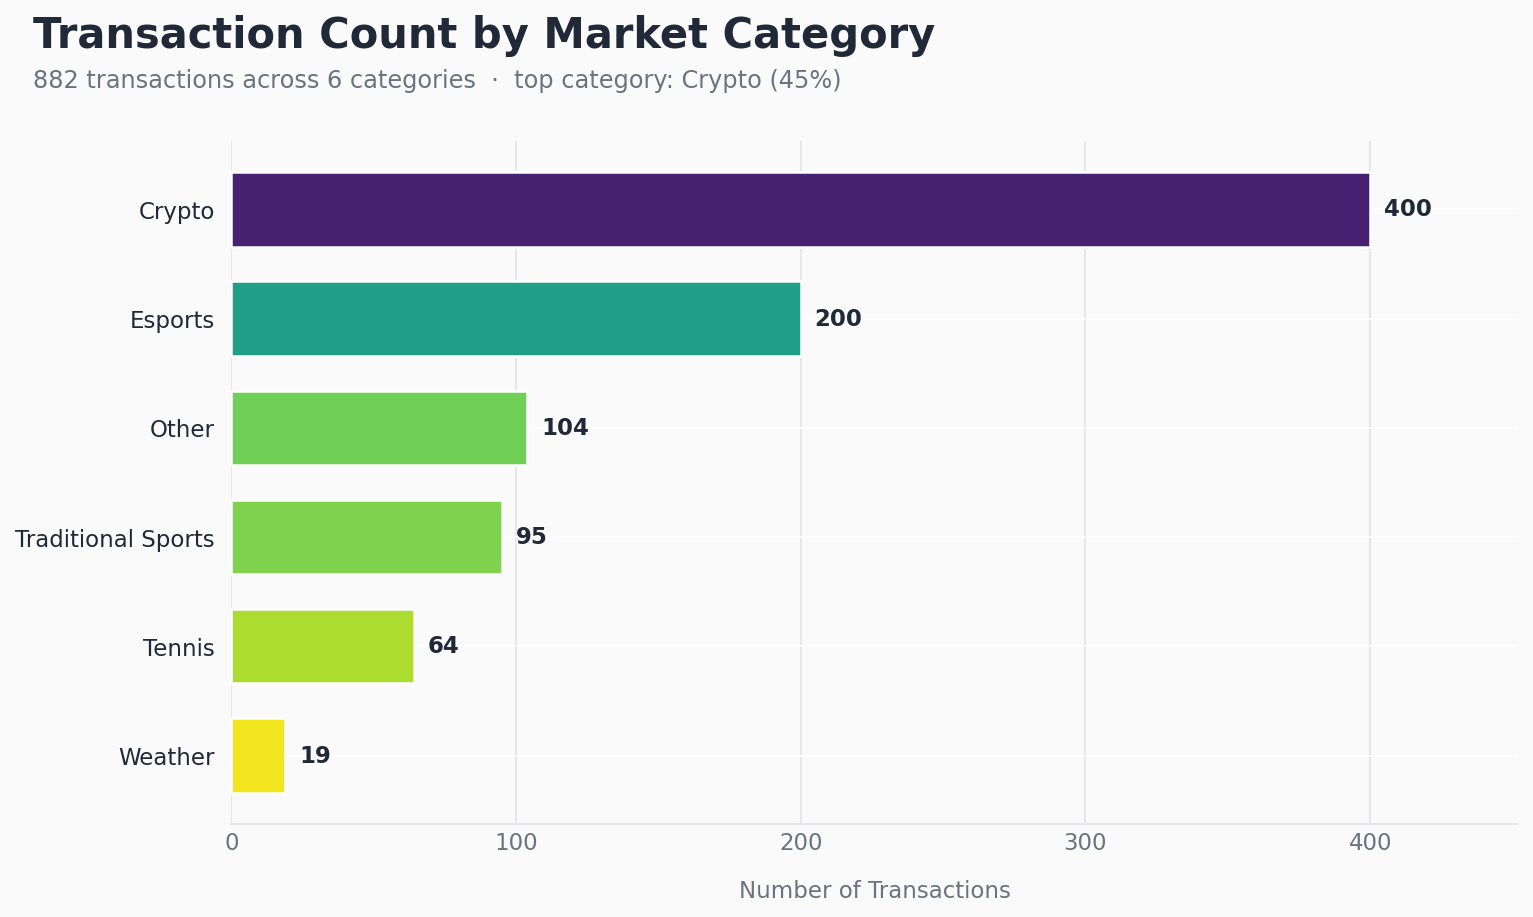

In [16]:
# Sort largest -> smallest (biggest bar on top)
order = np.argsort(counts)[::-1]
categories = [categories[i] for i in order]
counts = [counts[i] for i in order]

# Style
BG, TEXT, MUTED, GRID = "#FAFAFB", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.edgecolor": GRID,
    "text.color": TEXT,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": TEXT,
})

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

# Color gradient by value
cmap = plt.colormaps["viridis_r"]
norm = plt.Normalize(min(counts) * 0.6, max(counts) * 1.1)
colors = [cmap(norm(c)) for c in counts]

bars = ax.barh(categories, counts, color=colors, height=0.68,
               edgecolor="white", linewidth=1.2, zorder=3)

# Value labels
max_c = max(counts)
for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max_c * 0.012,
            bar.get_y() + bar.get_height() / 2,
            f"{c:,}", va="center", ha="left",
            fontsize=11, fontweight="bold", color=TEXT)

# Axes cosmetics
ax.invert_yaxis()
ax.set_xlim(0, max_c * 1.13)

ax.xaxis.grid(True, color=GRID, linewidth=1, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=11)
ax.tick_params(axis="y", pad=8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_xlabel("Number of Transactions", fontsize=11, labelpad=12)

# Title + subtitle
total = sum(counts)
fig.text(0.06, 0.95, "Transaction Count by Market Category",
         fontsize=20, fontweight="bold", color=TEXT, ha="left", va="top")
fig.text(0.06, 0.895,
         f"{total:,} transactions across {len(categories)} categories  ·  "
         f"top category: {categories[0]} ({counts[0] / total:.0%})",
         fontsize=11.5, color=MUTED, ha="left", va="top")

fig.subplots_adjust(left=0.18, right=0.96, top=0.82, bottom=0.12)
plt.savefig("transactions_by_category.png", facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()